#Week 8: Comparative Analysis of PCA and Radon Orientation Estimation Methods

##1. Loading Required Libraries and Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pca_df = pd.read_csv("Week7_PCA_Results.csv")
radon_df = pd.read_csv("week6_radon_results.csv")

##2. Preprocessing and Merging Results

In [ ]:
pca_df["Image Key"] = pca_df["Source Image"].str.replace(".jpg", "", regex=False)
radon_df["Image Key"] = radon_df["Image"].str.replace(".jpg", "", regex=False)

comparison_df = pd.merge(
    pca_df,
    radon_df,
    left_on=["Image Key", "Vehicle Index"],
    right_on=["Image Key", "Vehicle"],
    suffixes=("_PCA", "_Radon"),
    validate="one_to_one"
)

comparison_df = comparison_df.rename(columns={
    "Error (degrees)": "PCA Error",
    "Radon Error": "Radon Error",
    "Type_PCA": "Type"
})

comparison_df["Difference"] = (
    comparison_df["PCA Error"] - comparison_df["Radon Error"]
)

print("Total matched vehicles:", len(comparison_df))
print("PCA MAE:", round(comparison_df["PCA Error"].mean(), 2), "degrees")
print("Radon MAE:", round(comparison_df["Radon Error"].mean(), 2), "degrees")

print("\nNumber of vehicles where each method performed better:")
print("PCA:", (comparison_df["Difference"] < 0).sum())
print("Radon:", (comparison_df["Difference"] > 0).sum())

Total matched vehicles: 240
PCA MAE: 5.6 degrees
Radon MAE: 4.79 degrees

Number of vehicles where each method performed better:
PCA: 105
Radon: 135


##3. Vehicle Type vs Orientation Error

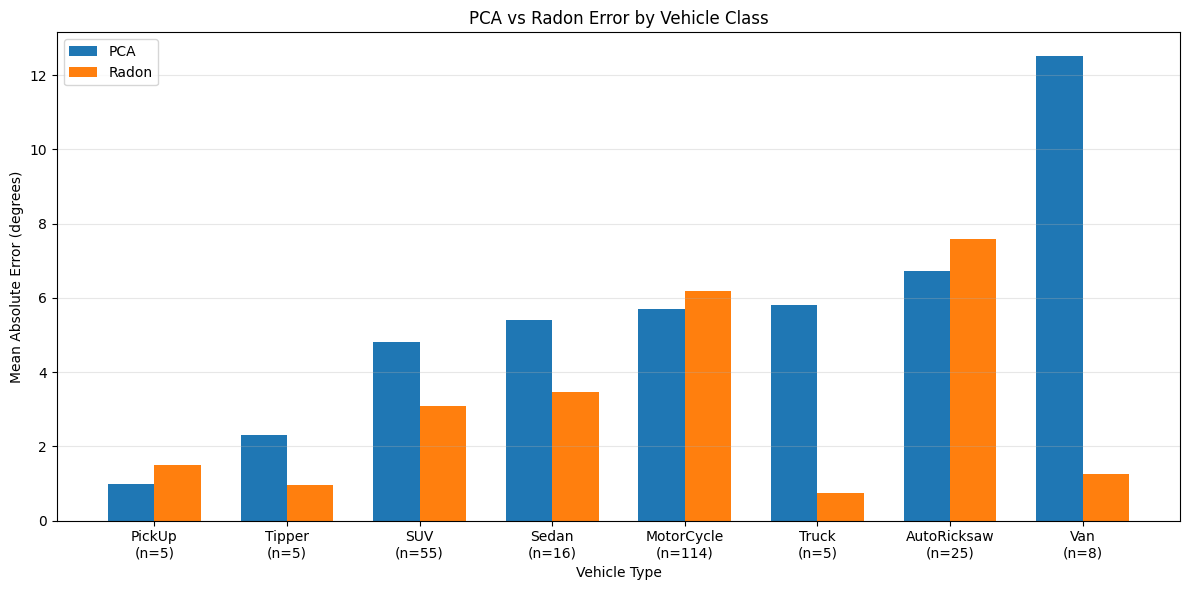

Vehicle Class Statistics:
               PCA  Radon  Count
Type                            
PickUp        0.97   1.49      5
Tanker        1.94   0.36      2
Tipper        2.31   0.95      5
Auto3WCargo   3.94   1.60      1
Container     4.52   0.66      2
SUV           4.82   3.09     55
Bus           5.16   1.20      1
Sedan         5.40   3.47     16
MotorCycle    5.69   6.18    114
Truck         5.80   0.73      5
AutoRicksaw   6.73   7.58     25
Trailer       7.47   0.02      1
Van          12.52   1.26      8

Classes with fewer than 5 samples:
              PCA  Radon  Count
Type                           
Tanker       1.94   0.36      2
Auto3WCargo  3.94   1.60      1
Container    4.52   0.66      2
Bus          5.16   1.20      1
Trailer      7.47   0.02      1


In [ ]:
class_errors = comparison_df.groupby("Type").agg(
    PCA=("PCA Error", "mean"),
    Radon=("Radon Error", "mean"),
    Count=("PCA Error", "count")
)

class_errors = class_errors.sort_values("PCA")

main_classes = class_errors[class_errors["Count"] >= 5]
rare_classes = class_errors[class_errors["Count"] < 5]

x = np.arange(len(main_classes))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    main_classes["PCA"],
    width,
    label="PCA"
)

plt.bar(
    x + width/2,
    main_classes["Radon"],
    width,
    label="Radon"
)

plt.xlabel("Vehicle Type")
plt.ylabel("Mean Absolute Error (degrees)")
plt.title("PCA vs Radon Error by Vehicle Class")

plt.xticks(
    x,
    [f"{name}\n(n={count})" for name, count in
     zip(main_classes.index, main_classes["Count"])]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Vehicle Class Statistics:")
print(class_errors.round(2).to_string())

print("\nClasses with fewer than 5 samples:")
print(rare_classes.round(2).to_string())

##4. Ground-truth Orientation vs Orientation Error

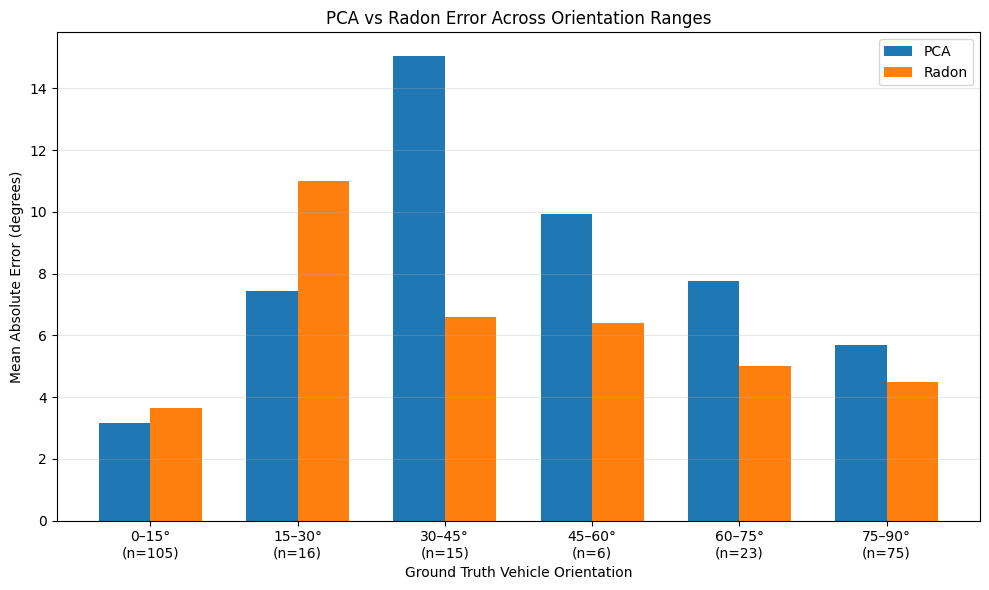

Orientation-wise Error Statistics:
               PCA  Radon  Count
Angle Range                     
0–15°         3.17   3.65    105
15–30°        7.43  11.00     16
30–45°       15.07   6.61     15
45–60°        9.92   6.39      6
60–75°        7.77   5.02     23
75–90°        5.69   4.50     75


In [ ]:
angle_bins = [0, 15, 30, 45, 60, 75, 90]
angle_labels = [
    "0–15°",
    "15–30°",
    "30–45°",
    "45–60°",
    "60–75°",
    "75–90°"
]

comparison_df["Angle Range"] = pd.cut(
    comparison_df["Ground Truth Axis (0-90)"],
    bins=angle_bins,
    labels=angle_labels,
    include_lowest=True
)

angle_errors = comparison_df.groupby(
    "Angle Range", observed=False
).agg(
    PCA=("PCA Error", "mean"),
    Radon=("Radon Error", "mean"),
    Count=("PCA Error", "count")
)

x = np.arange(len(angle_errors))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    angle_errors["PCA"],
    width,
    label="PCA"
)

plt.bar(
    x + width/2,
    angle_errors["Radon"],
    width,
    label="Radon"
)

plt.xlabel("Ground Truth Vehicle Orientation")
plt.ylabel("Mean Absolute Error (degrees)")
plt.title("PCA vs Radon Error Across Orientation Ranges")

plt.xticks(
    x,
    [f"{name}\n(n={count})" for name, count in
     zip(angle_errors.index, angle_errors["Count"])]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Orientation-wise Error Statistics:")
print(angle_errors.round(2).to_string())

##5. Flight Height vs Orientation Error

                Height   PCA  Radon
0bGO_UHlP_zpWU   47.09  7.47   3.00
0av2_F0GS_ESe2   63.11  4.30   3.31
0bL4_wk8I_7GPe   65.88  5.71   4.54
0Ago_SddH_jFbn   66.25  5.10   4.97
0B5X_l5jk_Fh2I   92.91  7.26   7.90


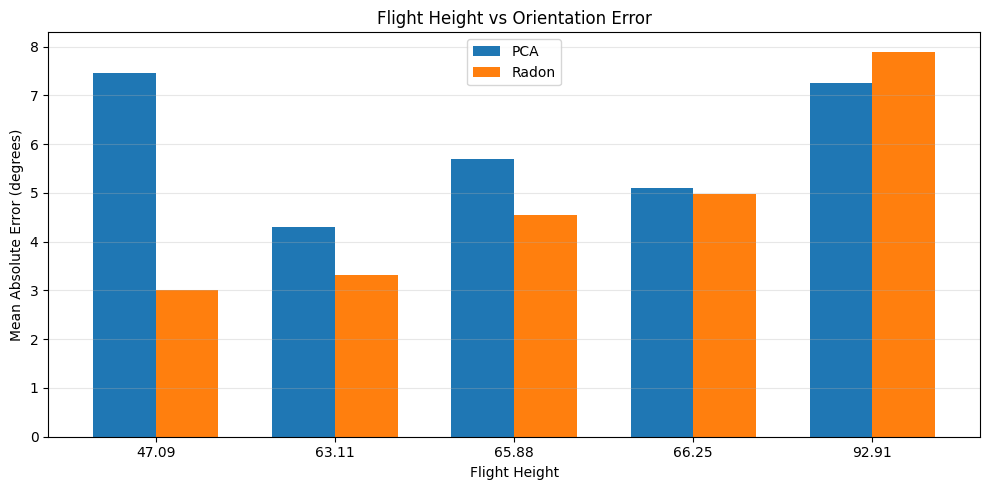

In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

pca = pd.read_csv("Week7_PCA_Results.csv")
radon = pd.read_csv("week6_radon_results.csv")

heights = {
    "0Ago_SddH_jFbn": 66.25,
    "0av2_F0GS_ESe2": 63.11,
    "0B5X_l5jk_Fh2I": 92.91,
    "0bGO_UHlP_zpWU": 47.09,
    "0bL4_wk8I_7GPe": 65.88
}

pca["Image"] = pca["Source Image"].str.replace(".jpg", "", regex=False)
radon["Image"] = radon["Image"].str.replace(".jpg", "", regex=False)

results = pd.DataFrame({
    "Height": pd.Series(heights),
    "PCA": pca.groupby("Image")["Error (degrees)"].mean(),
    "Radon": radon.groupby("Image")["Radon Error"].mean()
}).sort_values("Height")

print(results.round(2))

results[["PCA", "Radon"]].plot(kind="bar", figsize=(10, 5), width=0.7)
plt.xticks(range(5), [f"{h:.2f}" for h in results["Height"]], rotation=0)
plt.xlabel("Flight Height")
plt.ylabel("Mean Absolute Error (degrees)")
plt.title("Flight Height vs Orientation Error")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

